# Влияние прогноза времени доставки на оформление заказа

**Задача.** Проверить, может ли персонализированный прогноз времени быстрой доставки (ETA) повысить конверсию в заказ по сравнению с фиксированным обещанием 20–60 минут.

В исследовании рассмотрены исторические заказы, сессии, доставки и состав корзин. На их основе сформулированы метрики, условия A/B-теста и требования к событиям приложения. Данные о фактическом эксперименте в исходной выборке отсутствуют.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
conn = sqlite3.connect('eta_data.sqlite')
app_sess = pd.read_sql_query('SELECT * FROM app_sess', conn)
customers = pd.read_sql_query('SELECT * FROM customers', conn)
info = pd.read_sql_query('SELECT * FROM info', conn)
orders = pd.read_sql_query('SELECT * FROM orders', conn)
orders_product = pd.read_sql_query('SELECT * FROM orders_product', conn)
products = pd.read_sql_query('SELECT * FROM products', conn)
conn.close()
print('Сессии:',len(app_sess),'| Клиенты:', customers.customer_id.notna().sum(), '| Заказы:',len(orders),'| Записи доставок:',len(info))

Сессии: 5336 | Клиенты: 500 | Заказы: 2950 | Записи доставок: 3039


## Достоверность исходных данных

До выбора метрик проверены типы дат, полнота связей и повторные записи о доставке. Строки доставки и заказы — разные сущности: одну покупку могут сопровождать несколько записей в `info`.

In [2]:
customers = customers.dropna(subset=['customer_id']).copy()
for table, cols in [(orders,['order_id','customer_id']), (info,['order_id']), (orders_product,['order_id','product_id']), (products,['product_id'])]:
    for col in cols: table[col] = pd.to_numeric(table[col], errors='coerce')
orders['order_dt'] = pd.to_datetime(orders['order_dt'], dayfirst=True, errors='coerce')
info['delivery_dt'] = pd.to_datetime(info['delivery_dt'], dayfirst=True, errors='coerce')
for col in ['start_dttm','finish_dttm']:
    app_sess[col] = pd.to_datetime(app_sess[col], dayfirst=True, errors='coerce', format='%d.%m.%y %H:%M')
print('Сессии без валидного времени начала:',app_sess.start_dttm.isna().sum())
print('Заказы с отсутствующим клиентом:',(~orders.customer_id.isin(customers.customer_id)).sum())
print('Заказы без информации о доставке:', orders.order_id.nunique()-orders.order_id.isin(info.order_id).sum())
repeated = info.groupby('order_id').size()
print('Заказы с повторными строками доставки:',int((repeated>1).sum()))

Сессии без валидного времени начала: 42
Заказы с отсутствующим клиентом: 5
Заказы без информации о доставке: 1079
Заказы с повторными строками доставки: 815


In [3]:
delivery_status=info.assign(completed=info['is_completed_flg'].astype(str).str.lower().eq('true')).groupby('order_id',as_index=False)['completed'].max()
orders_with_info = delivery_status.order_id.nunique()
complete = int(delivery_status.completed.sum())
print('Заказы с записью о доставке:',orders_with_info)
print('С хотя бы одной завершённой доставкой:',complete)
print('Доля завершённых среди заказов с известным статусом: {:.1%}'.format(complete/orders_with_info))

Заказы с записью о доставке: 1871
С хотя бы одной завершённой доставкой: 0
Доля завершённых среди заказов с известным статусом: 0.0%


In [4]:
order_items=orders_product.merge(products[['product_id','Price']], on='product_id', how='left')
order_items['line_total']=order_items['amount']*order_items['Price']
order_total=order_items.groupby('order_id')['line_total'].sum()
print('Средний размер корзины по доступным заказам: {:,.0f}'.format(order_total.mean()))
print('Медианный размер корзины: {:,.0f}'.format(order_total.median()))

Средний размер корзины по доступным заказам: 496,129
Медианный размер корзины: 60,020


### Данные для тестирования

В исторических таблицах нет метки контрольной/тестовой группы, событий **показа ETA**, предлагаемого и фактического времени доставки в минутах. `order_dt` и `delivery_dt` — даты без времени, поэтому оценить попадание в обещанный интервал доставки невозможно. Это не результаты A/B-теста; вычисленные показатели описывают доступную историческую выборку.

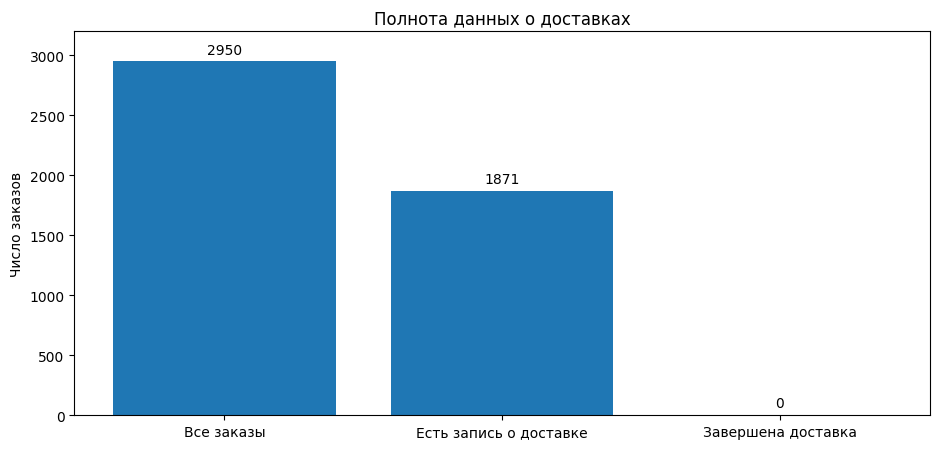

In [5]:
counts=pd.Series({'Все заказы':orders.order_id.nunique(), 'Есть запись о доставке':orders_with_info, 'Завершена доставка':complete})
plt.figure(figsize=(9.5,4.6))
bars=plt.bar(counts.index,counts.values)
for bar,v in zip(bars,counts.values):
    plt.text(bar.get_x()+bar.get_width()/2, v+40, str(v), ha='center', va='bottom')
plt.ylim(0,3200); plt.ylabel('Число заказов'); plt.title('Полнота данных о доставках')
plt.tight_layout(); plt.savefig('order_status.png',dpi=160); plt.show()

## Предложенный A/B-эксперимент

**Контроль:** фиксированный интервал «20–60 минут». **Тест:** рассчитанный моделью ETA.

- Единица случайного распределения — `customer_id`; 50/50. Группа закрепляется за пользователем на весь эксперимент.
- **Основная метрика** — конверсия из показа ETA на странице выбора магазина в оформленный заказ быстрой доставки, по уникальным пользователям за заранее выбранное окно наблюдения.
- **Защитные метрики** — доля выполненных заказов, доля доставок позже обещанного времени, средний чек; возможное ухудшение требует отдельного решения.
- Для анализа также нужны фактическая длительность доставки, попадание в обещанный ETA, длина показанного интервала и разрезы по устройствам/магазинам.

До запуска нужно выбрать длительность и минимально значимый эффект, рассчитать необходимое число пользователей и согласовать правило остановки. По приведённой исторической выборке размер эксперимента надёжно не оценить: нет репрезентативных показов ETA и конверсии на них.

## Решение по запуску

По имеющимся данным можно описать подход к A/B-тесту и требования к инструментированию, **но нельзя сделать вывод, эффективнее ли персонализированный ETA старого интервала**. Следующий этап — добавить события показа прогноза и фактических минут доставки, проверить качество разбиения пользователей и провести эксперимент.